In [ ]:
import napari
import numpy as np
from skimage import io
import matplotlib.pyplot as plt

from nd2reader import ND2Reader
import h5py
import numpy as np
import os
import glob


### Crop Experiment data

In [46]:
HEADPATH = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Drift_Correction/'
nd2_filename = HEADPATH + 'Experiment_crop_FOV-All_T-Last.nd2'
output_filename = HEADPATH + 'Experiment_crop_FOV-All_T-Last_For-Drift.hdf5'

# Define the cropping parameters as variables
crop_x = 1000  # Replace with your desired top-left x-coordinate
crop_y = 650  # Replace with your desired top-left y-coordinate
crop_width = 400  # Replace with your desired width
crop_height = 450 # Replace with your desired height


In [48]:
def crop_single_fov_from_nd2(nd2_filename,
                            fov_index,
                            do_cropping,
                            crop_x,
                            crop_y,
                            crop_width,
                            crop_height):

    with ND2Reader(nd2_filename) as nd2file:
        num_views = nd2file.sizes['v']
        first_frame = nd2file.get_frame_2D(t=0, v=0)
        dtype = first_frame.dtype

        frame = nd2file.get_frame_2D(t=0, v=v)

        if do_cropping:
            frame = frame[crop_y:crop_y + crop_height, crop_x:crop_x + crop_width]

    return frame

def crop_all_fovs_from_nd2(nd2_filename,
                            do_cropping,
                            crop_x,
                            crop_y,
                            crop_width,
                            crop_height):
    with ND2Reader(nd2_filename) as nd2file:
        # Get the number of views (positions) from the ND2 file metadata
        num_views = nd2file.sizes['v']
        first_frame = nd2file.get_frame_2D(t=0, v=0)
        dtype = first_frame.dtype
        # Preallocate the 3D NumPy array
        cropped_array_3D = np.empty((num_views, crop_height, crop_width), dtype=dtype)

        # Iterate through each view (since there is only one timepoint: t=0)
        for v in range(num_views):
            # Get the 2D frame for the current view at timepoint 0
            frame = nd2file.get_frame_2D(t=0, v=v)
            # Crop the image
            cropped_array_3D[v, :, :] = frame[crop_y:crop_y + crop_height, crop_x:crop_x + crop_width]
            print(v)
        return cropped_array_3D

In [ ]:
frame = crop_single_fov_from_nd2(
    nd2_filename=nd2_filename,
    fov_index=0,
    do_cropping=True,
    crop_x=crop_x,
    crop_y=crop_y,
    crop_width=crop_width,
    crop_height=crop_height
)

plt.imshow(cropped_array_3D[3], cmap='gray')

In [49]:
cropped_array_3D = crop_all_fovs_from_nd2(
    nd2_filename,
    do_cropping=True,
    crop_x=crop_x,
    crop_y=crop_y,
    crop_width=crop_width,
    crop_height=crop_height
)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

In [50]:
# # Open the HDF5 file for writing
with h5py.File(output_filename, 'w') as hf:
    # Create a single dataset in the HDF5 file and write the 3D array
    hf.create_dataset('data', data=cropped_array_3D)
    print(f"Saved the 3D array to dataset 'data' in: {output_filename}")

Saved the 3D array to dataset 'data' in: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Drift_Correction/Experiment_crop_FOV-All_T-Last_For-Drift.hdf5


### Crop Barcode data

In [64]:
HEADPATH = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/'
output_filename = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Drift_Correction/Barcodes_crop_FOV-All_T-Last_For-Drift.hdf5'

In [66]:
def get_barcode_file_list_for_alignment(headpath,
                                        filename_pattern):
    filename_pattern = "fov=*_config=SEG_t=1.hdf5"
    # Find all files matching the pattern
    file_list = glob.glob(os.path.join(HEADPATH, filename_pattern))
    # Sort the file list to ensure consistent ordering accounting for numbers
    file_list.sort(key=lambda x: int(x.split('fov=')[1].split('_')[0])) 
    print(len(file_list), "files found matching the pattern.")

    return file_list

In [74]:
def crop_all_fovs_from_hdf5_files(file_list,
                                   do_cropping,
                                   crop_x,
                                   crop_y,
                                   crop_width,
                                   crop_height):
    with h5py.File(file_list[0], 'r') as file:
        # Read the first file to determine the shape and dtype
        dtype = file['data'].dtype

    # Preallocate the 3D NumPy array
    num_files = len(file_list)
    cropped_array_3D = np.empty((num_files, crop_height, crop_width), dtype=dtype)

    for i, file_path in enumerate(file_list):
        with h5py.File(file_path, 'r') as hf:
            # Read the dataset from the HDF5 file
            data = hf['data'][:]
            # Crop the image
            cropped_array_3D[i, :, :] = data[crop_y:crop_y + crop_height, crop_x:crop_x + crop_width]
            print(f"Processed file {i+1}/{num_files}: {file_path}")

    return cropped_array_3D

In [67]:
file_list= get_barcode_file_list_for_alignment(
    headpath=HEADPATH,
    filename_pattern="fov=*_config=SEG_t=1.hdf5"
)

629 files found matching the pattern.


In [73]:
cropped_array_3D[0]

array([[ 78,  90, 143, ..., 124,  67,  73],
       [  2, 119, 117, ...,  90, 206,  89],
       [  7,  56, 179, ..., 125,  85, 154],
       ...,
       [  7, 244,  83, ..., 248,  49, 149],
       [ 89, 171,  23, ..., 144, 130, 137],
       [104, 241, 109, ..., 175, 209,  12]], shape=(450, 400), dtype=uint8)

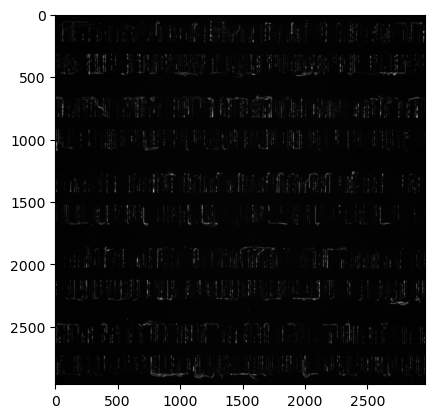

In [72]:
with h5py.File(file_list[0], 'r') as file:
    # Read the first file to determine the shape and dtype
    dtype = file['data'].dtype
    plt.imshow(file['data'], cmap='gray')

In [75]:
cropped_array_3D = crop_all_fovs_from_hdf5_files(
    file_list=file_list,
    do_cropping=True,
    crop_x=crop_x,
    crop_y=crop_y,
    crop_width=crop_width,
    crop_height=crop_height
)

Processed file 1/629: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=0_config=SEG_t=1.hdf5
Processed file 2/629: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=1_config=SEG_t=1.hdf5
Processed file 3/629: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=2_config=SEG_t=1.hdf5
Processed file 4/629: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=3_config=SEG_t=1.hdf5
Processed file 5/629: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=4_config=SEG_t=1.hdf5
Processed file 6/629: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=5_config=SEG_t=1.hdf5
Processed file 7/629: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fov=6_config=SEG_t=1.hdf5
Processed file 8/629: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/fo

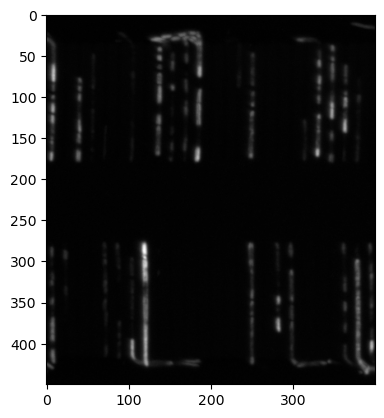

In [78]:
plt.imshow(cropped_array_3D[1], cmap='gray')

In [79]:
output_filename = '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Drift_Correction/Barcodes_crop_FOV-All_T-Last_For-Drift.hdf5'

In [80]:
# # Open the HDF5 file for writing
with h5py.File(output_filename, 'w') as hf:
    # Create a single dataset in the HDF5 file and write the 3D array
    hf.create_dataset('data', data=cropped_array_3D)
    print(f"Saved the 3D array to dataset 'data' in: {output_filename}")

print("Cropping, stacking, and saving to HDF5 complete.")

Saved the 3D array to dataset 'data' in: /home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Drift_Correction/Barcodes_crop_FOV-All_T-Last_For-Drift.hdf5
Cropping, stacking, and saving to HDF5 complete.


### Open Napari Interface

Use the file:

`/home/lag36/lag_paulsson-lab/misc/2025-06-28_Manual-Drift-Recording/2025-07-03_Drift-Recording-Cropped-Images.ipynb`